# Deep Learning Image Classification Project: Fashion-MNIST

## 1. Project Objective
The objective of this project is to implement, evaluate, and compare **Deep Learning neural network architectures** using **TensorFlow and Keras** on the Fashion-MNIST dataset. Each item is a $28 \times 28$ grayscaled image containing $784$ pixels with values from $[0, 255]$ representing clothing textures. The models objective is to learn spatial hierarchies, edges, and textures from the pixel matrices to place them in the correct category.

### Business Impact
- **Reduced Operational Costs**: Minimal manual labeling costs.
- **Faster Times**: New catalog lines are indexed in seconds.

We will build, train, and compare the following Deep Learning models:
1. **Baseline MLP**
2. **Simple CNN**
3. **Deep CNN**

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

## 2. Dataset Description & Exploratory Data Analysis
The dataset selected for this project is **Fashion-MNIST**, composed of grayscaled images of clothing items across the following classes:

- `0`: T-shirt/top
- `1`: Trouser
- `2`: Pullover
- `3`: Dress
- `4`: Coat
- `5`: Sandal
- `6`: Shirt
- `7`: Sneaker
- `8`: Bag
- `9`: Ankle boot

In [3]:
# Load dataset
(X_train_raw, y_train), (X_test_raw, y_test) = tf.keras.datasets.fashion_mnist.load_data()

class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

### Data Preprocessing & Feature Engineering
1. **Normalization**: Values ranging from $[0, 255]$ are divided by $255.0$ to scale features between $[0.0, 1.0]$.
2. **Channel Reshaping**: Grayscale arrays of shape `(28, 28)` are expanded to `(28, 28, 1)` because input needs to be in `(height, width, channel)` format.

In [5]:
# Rescaling and adding channel dimension
X_train = (X_train_raw / 255.0)[:, :, :, np.newaxis]
X_test = (X_test_raw / 255.0)[:, :, :, np.newaxis]

## 3. Deep Learning Model Development & Variations
We train three distinct variations using the `adam` optimizer and `sparse_categorical_crossentropy` loss over 5 epochs with a batch size of 64 and a 10% validation split.

### Model 1: Baseline MLP

In [8]:
mlp = models.Sequential([layers.Input(shape=((28, 28, 1))), layers.Flatten(), layers.Dense(128, activation='relu'), layers.Dense(10, activation='softmax')], name="Baseline_MLP")

mlp.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

mlp_model = mlp.fit(X_train, y_train, epochs=5, batch_size=64, validation_split=0.1, verbose=1)

Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.8156 - loss: 0.5317 - val_accuracy: 0.8470 - val_loss: 0.4269
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.8607 - loss: 0.3925 - val_accuracy: 0.8612 - val_loss: 0.3904
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.8746 - loss: 0.3511 - val_accuracy: 0.8738 - val_loss: 0.3531
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.8834 - loss: 0.3228 - val_accuracy: 0.8628 - val_loss: 0.3788
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.8889 - loss: 0.3052 - val_accuracy: 0.8768 - val_loss: 0.3342


### Model 2: Simple CNN (Single Conv + Pooling)

In [ ]:
simple_cnn = models.Sequential([layers.Input(shape=(28, 28, 1)), layers.Conv2D(32, (3, 3), activation='relu'), layers.MaxPooling2D((2, 2)), layers.Flatten(), layers.Dense(64, activation='relu'), layers.Dense(10, activation='softmax')], name="Simple_CNN")

simple_cnn.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

simple_cnn_model = simple_cnn.fit(X_train, y_train, epochs=5, batch_size=64, validation_split=0.1, verbose=1)

Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 26s 30ms/step - accuracy: 0.8343 - loss: 0.4705 - val_accuracy: 0.8820 - val_loss: 0.3431
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 40s 29ms/step - accuracy: 0.8896 - loss: 0.3123 - val_accuracy: 0.8977 - val_loss: 0.2916
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 25s 30ms/step - accuracy: 0.9051 - loss: 0.2706 - val_accuracy: 0.9058 - val_loss: 0.2720
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 40s 29ms/step - accuracy: 0.9128 - loss: 0.2405 - val_accuracy: 0.8988 - val_loss: 0.2750
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 42s 30ms/step - accuracy: 0.9212 - loss: 0.2180 - val_accuracy: 0.9092 - val_loss: 0.2483


### Model 3: Deep CNN

In [ ]:
deep_cnn = models.Sequential([layers.Input(shape=(28, 28, 1)), layers.Conv2D(32, (3, 3), activation='relu'), layers.MaxPooling2D((2, 2)), layers.Conv2D(64, (3, 3), activation='relu'), layers.MaxPooling2D((2, 2)), layers.Flatten(), layers.Dropout(0.5), layers.Dense(128, activation='relu'), layers.Dropout(0.2), layers.Dense(10, activation='softmax')], name="Deep_CNN")

deep_cnn.compile(optimizer='adam',loss='sparse_categorical_crossentropy', metrics=['accuracy'])

deep_cnn_model = deep_cnn.fit(X_train, y_train, epochs=5, batch_size=64, validation_split=0.1, verbose=1)

Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 46s 53ms/step - accuracy: 0.7883 - loss: 0.5778 - val_accuracy: 0.8635 - val_loss: 0.3766
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 43s 51ms/step - accuracy: 0.8553 - loss: 0.3960 - val_accuracy: 0.8798 - val_loss: 0.3247
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 82s 52ms/step - accuracy: 0.8710 - loss: 0.3483 - val_accuracy: 0.8927 - val_loss: 0.2918
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 43s 51ms/step - accuracy: 0.8822 - loss: 0.3184 - val_accuracy: 0.8982 - val_loss: 0.2800
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 43s 51ms/step - accuracy: 0.8889 - loss: 0.2983 - val_accuracy: 0.9040 - val_loss: 0.2688


## 4. Model Evaluation & Comparison

In [ ]:
# Predictions
mlp_pred = np.argmax(mlp.predict(X_test), axis=1)
simple_cnn_pred = np.argmax(simple_cnn.predict(X_test), axis=1)
deep_cnn_pred = np.argmax(deep_cnn.predict(X_test), axis=1)

# Evaluate metrics
mlp_loss, mlp_accuracy = mlp.evaluate(X_test, y_test, verbose=0)
simple_cnn_loss, simple_cnn_accuracy = simple_cnn.evaluate(X_test, y_test, verbose=0)
deep_cnn_loss, deep_cnn_accuracy = deep_cnn.evaluate(X_test, y_test, verbose=0)

df = pd.DataFrame({"Baseline MLP": [mlp_loss, mlp_accuracy], "Simple CNN": [simple_cnn_loss, simple_cnn_accuracy], "Deep CNN": [deep_cnn_loss, deep_cnn_accuracy]}, index=["Loss", "Accuracy"])

df

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step


,Baseline MLP,Simple CNN,Deep CNN
Loss,0.364078,0.26713,0.283107
Accuracy,0.867500,0.90530,0.897400


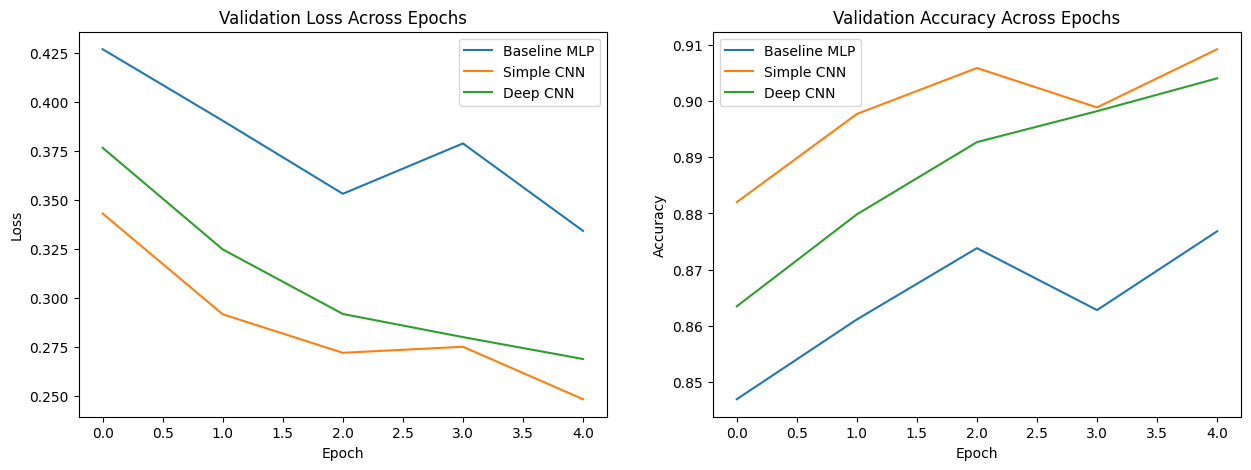

In [ ]:
# Loss and Accuracy across training epochs
plt.figure(figsize=(15, 5))

plt.subplot(1, 2, 1)
plt.plot(mlp_model.history['val_loss'], label='Baseline MLP')
plt.plot(simple_cnn_model.history['val_loss'], label='Simple CNN')
plt.plot(deep_cnn_model.history['val_loss'], label='Deep CNN')
plt.title('Validation Loss Across Epochs')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(mlp_model.history['val_accuracy'], label='Baseline MLP')
plt.plot(simple_cnn_model.history['val_accuracy'], label='Simple CNN')
plt.plot(deep_cnn_model.history['val_accuracy'], label='Deep CNN')
plt.title('Validation Accuracy Across Epochs')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.show()

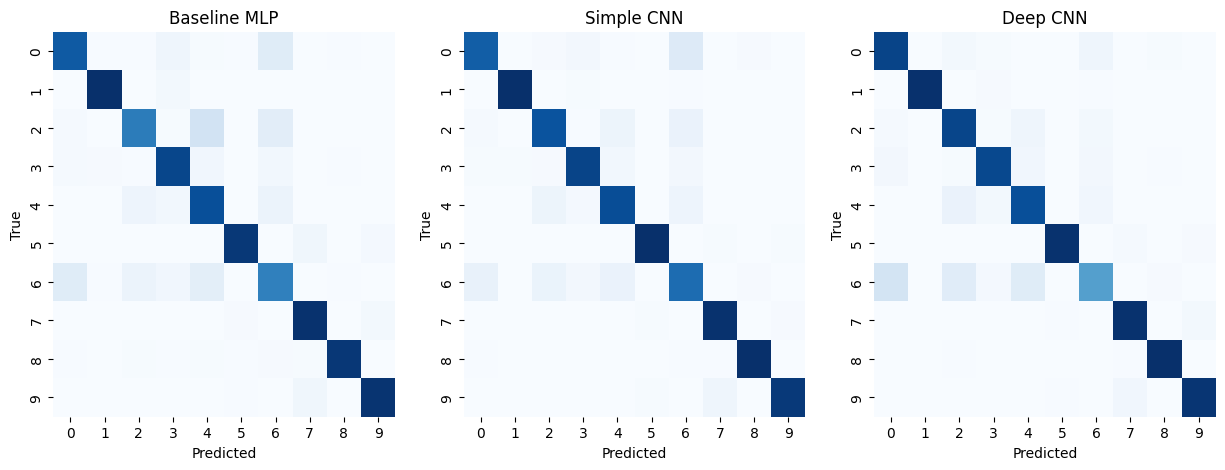

In [ ]:
# Confusion matrices
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

mlp_matrix = confusion_matrix(y_test, mlp_pred)
sns.heatmap(mlp_matrix, annot=False, cmap='Blues', ax=axes[0], cbar=False)
axes[0].set_title("Baseline MLP")
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('True')

simple_cnn_matrix = confusion_matrix(y_test, simple_cnn_pred)
sns.heatmap(simple_cnn_matrix, annot=False, cmap='Blues', ax=axes[1], cbar=False)
axes[1].set_title("Simple CNN")
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('True')

deep_cnn_matrix = confusion_matrix(y_test, deep_cnn_pred)
sns.heatmap(deep_cnn_matrix, annot=False, cmap='Blues', ax=axes[2], cbar=False)
axes[2].set_title("Deep CNN")
axes[2].set_xlabel('Predicted')
axes[2].set_ylabel('True')

plt.show()

### Model Performance & Best Model

**Baseline MLP** has the lowest accuracy of the 3 models (~$86.7\%$).

**Simple CNN** is the recommended model which achieves the highest accuracy (~$90.5\%$).

**Deep CNN** is close second with an accuracy of (~$89.7\%$).

## 5. Key Findings

- CNNs show better results over MLPs which means the convolutions are essential for image processing.

## 6. Limitations & Future Steps

### Limitations
- **Low Resolution & Grayscale**: Real e-commerce catalog photos are high-resolution and multi-channeled RGB.

### Future Steps
- **Data Augmentation**: Use horizontal flips, zooms, and rotations during training to improve against real-world photo variations.